# Exploratory Data Analysis: Superstore Retail Sales
**Datheon Data Analytics & Power BI Internship, Task 1**

**Goal:** analyse customer purchase volume, monthly seasonality, category-wise revenue and discount sensitivity, then summarise the results as executive takeaways.

**Approach:** load and wrangle the data, profile missing values, parse dates, aggregate by Category / Region / Segment, visualise sales trends and discount-vs-profit, then document the business observations.

## 1. Setup and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.2f}".format

raw = pd.read_csv("superstore_sales.csv")
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.00,0.00,219.58
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5.00,0.45,-383.03
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52


## 2. Data wrangling and quality checks
### 2.1 Missing-value profile of the raw file

In [2]:
missing = raw.isna().sum().to_frame("missing_count")
missing["missing_pct"] = missing["missing_count"] / len(raw) * 100
missing[missing["missing_count"] > 0]

,missing_count,missing_pct
Order Date,806,7.46
Ship Date,806,7.46
Ship Mode,806,7.46
Customer ID,806,7.46
Customer Name,806,7.46
Segment,806,7.46
Country,806,7.46
City,806,7.46
State,806,7.46
Postal Code,817,7.56


Nearly every column has the **same 806 missing values**, which points to a structural problem rather than random gaps. Let's look at those rows.

In [3]:
junk = raw[raw["Sales"].isna()]
print("Rows with no sales data:", len(junk))
junk.iloc[:, :3].iloc[[0, 1, 4, 5, 6, 7]]

Rows with no sales data: 806


,Row ID,Order ID,Order Date
9994,Person,Region,NaN
9995,Anna Andreadi,West,NaN
9998,Cassandra Brandow,South,NaN
9999,Returned,Order ID,NaN
10000,Yes,CA-2015-100762,NaN
10001,Yes,CA-2015-100762,NaN


**Finding:** the file has extra tables appended below the real sales data. These are a *People* table (regional managers) and a *Returns* table (returned order IDs), and they were pasted into the same sheet. They are not sales transactions, so I split them out:

- the **sales transactions** (the rows that have a `Sales` value) form the analysis dataset
- the **returns** table is kept separately, so return rates can be checked later

In [4]:
# Split the appended tables out of the main data
returns_start = raw.index[raw["Row ID"] == "Returned"][0]
returned_ids = set(raw.loc[returns_start + 1:, "Order ID"].dropna())

df = raw.dropna(subset=["Sales"]).copy()
print("Sales rows:", len(df), "| distinct returned orders in returns table:", len(returned_ids))

Sales rows: 9994 | distinct returned orders in returns table: 296


### 2.2 Remaining nulls and duplicates

In [5]:
print("Remaining nulls:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nCities with a missing Postal Code:", df.loc[df["Postal Code"].isna(), "City"].unique())

# Duplicates ignoring the Row ID (which is unique by construction)
dup_cols = [c for c in df.columns if c != "Row ID"]
print("Duplicate transactions:", df.duplicated(subset=dup_cols).sum())

Remaining nulls:
Postal Code    11
dtype: int64

Cities with a missing Postal Code: <StringArray>
['Burlington']
Length: 1, dtype: str
Duplicate transactions: 1


In [6]:
# Fix: Burlington (VT) postal code is missing, fill it; drop exact duplicate transactions
df.loc[(df["City"] == "Burlington") & (df["Postal Code"].isna()), "Postal Code"] = 5401
df = df.drop_duplicates(subset=dup_cols).copy()

# Tidy types
df["Postal Code"] = df["Postal Code"].astype(int)
df["Quantity"] = df["Quantity"].astype(int)
df["Row ID"] = df["Row ID"].astype(int)
print("Clean shape:", df.shape)

Clean shape: (9993, 21)


### 2.3 Parse dates and engineer features

In [7]:
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Year-Month"] = df["Order Date"].dt.to_period("M")
df["Ship Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Profit Margin"] = df["Profit"] / df["Sales"]

print("Date range:", df["Order Date"].min().date(), "to", df["Order Date"].max().date())
print("Any ship date before order date:", (df["Ship Days"] < 0).any())
print("Discounts within 0-100%:", df["Discount"].between(0, 1).all())
df.describe().T[["count", "mean", "min", "max"]]

Date range: 2015-01-03 to 2018-12-30
Any ship date before order date: False
Discounts within 0-100%: True


,count,mean,min,max
Row ID,"9,993.00","4,997.66",1.00,"9,994.00"
Order Date,9993,2017-04-30 07:03:30.747523,2015-01-03 00:00:00,2018-12-30 00:00:00
Ship Date,9993,2017-05-04 06:03:42.635845,2015-01-07 00:00:00,2019-01-05 00:00:00
Postal Code,"9,993.00","55,191.57","1,040.00","99,301.00"
Sales,"9,993.00",229.85,0.44,"22,638.48"
Quantity,"9,993.00",3.79,1.00,14.00
Discount,"9,993.00",0.16,0.00,0.80
Profit,"9,993.00",28.66,"-6,599.98","8,399.98"
Year,"9,993.00","2,016.72","2,015.00","2,018.00"
Month,"9,993.00",7.81,1.00,12.00


## 3. Business overview

In [8]:
total_sales, total_profit = df["Sales"].sum(), df["Profit"].sum()
kpis = pd.Series({
    "Total Sales": total_sales,
    "Total Profit": total_profit,
    "Overall Profit Margin %": total_profit / total_sales * 100,
    "Orders": df["Order ID"].nunique(),
    "Customers": df["Customer ID"].nunique(),
    "Average Discount %": df["Discount"].mean() * 100,
})
kpis.to_frame("Value")

,Value
Total Sales,"2,296,919.49"
Total Profit,"286,409.08"
Overall Profit Margin %,12.47
Orders,"5,009.00"
Customers,793.00
Average Discount %,15.62


## 4. Customer purchase volume

Median orders per customer: 6.0
Customers with more than one order: 98.5%
Top 10% of customers' share of sales: 30.6%


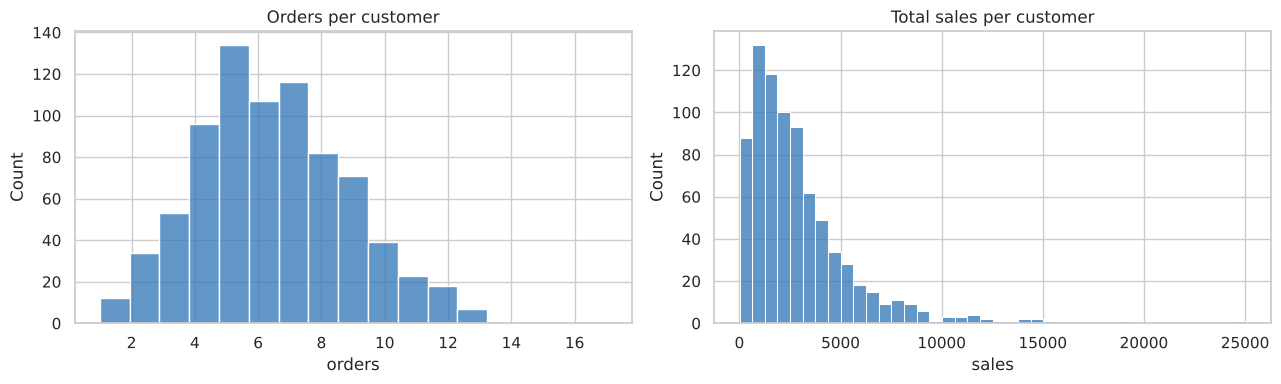

,orders,sales,profit
Customer ID,,,
SM-20320,5,"25,043.05","-1,980.74"
TC-20980,5,"19,052.22","8,981.32"
RB-19360,6,"15,117.34","6,976.10"
TA-21385,4,"14,595.62","4,703.79"
AB-10105,10,"14,473.57","5,444.81"
KL-16645,12,"14,175.23",806.86
SC-20095,9,"14,142.33","5,757.41"
HL-15040,6,"12,873.30","5,622.43"
SE-20110,11,"12,209.44","2,650.68"


In [9]:
cust = df.groupby("Customer ID").agg(
    orders=("Order ID", "nunique"),
    sales=("Sales", "sum"),
    profit=("Profit", "sum"),
)

print("Median orders per customer:", cust["orders"].median())
print("Customers with more than one order: {:.1%}".format((cust["orders"] > 1).mean()))

top10 = cust.sort_values("sales", ascending=False).head(int(len(cust) * 0.10))
print("Top 10% of customers' share of sales: {:.1%}".format(top10["sales"].sum() / cust["sales"].sum()))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(cust["orders"], bins=17, ax=ax[0], color="#2E75B6")
ax[0].set_title("Orders per customer")
sns.histplot(cust["sales"], bins=40, ax=ax[1], color="#2E75B6")
ax[1].set_title("Total sales per customer")
plt.tight_layout()
plt.show()

cust.sort_values("sales", ascending=False).head(10)

## 5. Monthly sales velocity and seasonality

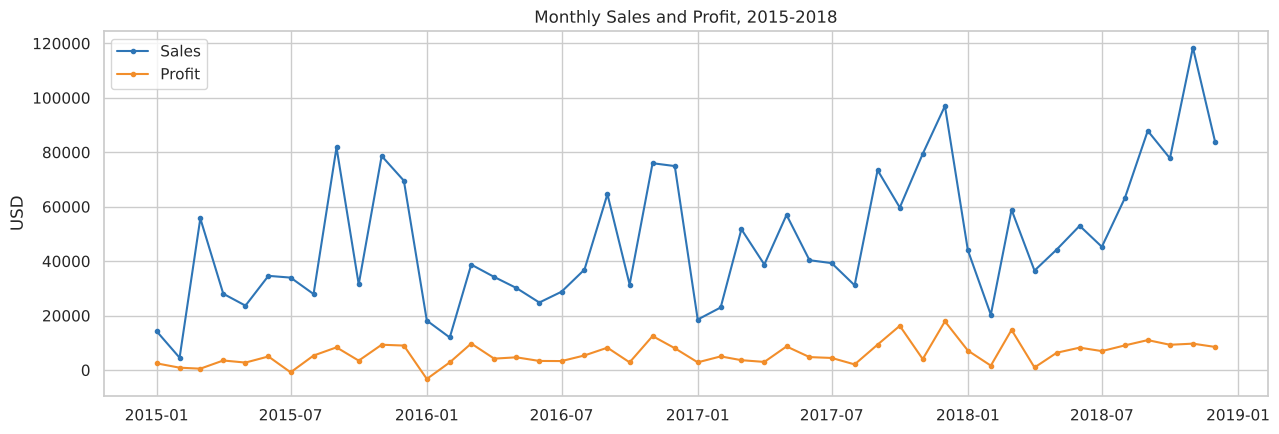

In [10]:
monthly = df.groupby("Year-Month")[["Sales", "Profit"]].sum()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(monthly.index, monthly["Sales"], marker="o", ms=3, label="Sales", color="#2E75B6")
ax.plot(monthly.index, monthly["Profit"], marker="o", ms=3, label="Profit", color="#F28E2B")
ax.set_title("Monthly Sales and Profit, 2015-2018")
ax.set_ylabel("USD")
ax.legend()
plt.tight_layout()
plt.show()

,Sales,Profit,Sales growth %,Margin %
Year,,,,
2015,"483,966.13","49,556.03",NaN,10.24
2016,"470,532.51","61,618.60",-2.78,13.10
2017,"609,205.60","81,795.17",29.47,13.43
2018,"733,215.26","93,439.27",20.36,12.74


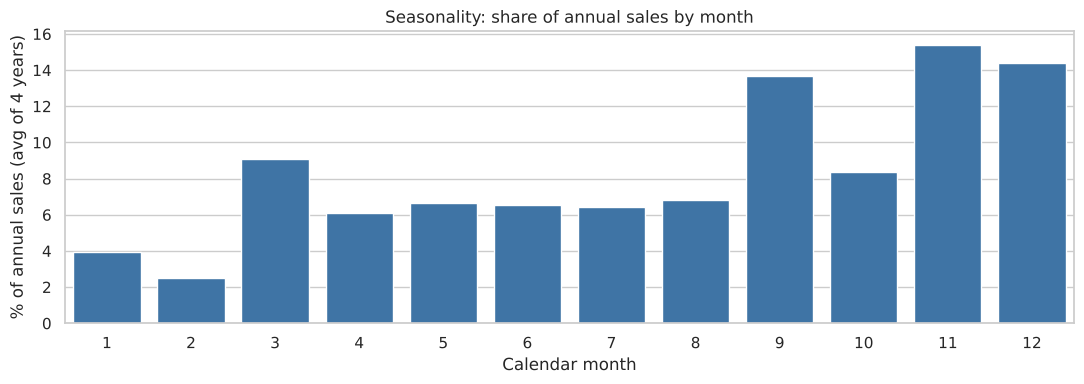

Q4 (Oct-Dec) share of sales: 38.2%
Sept + Nov + Dec share of sales: 42.9%


In [11]:
# Yearly growth
yearly = df.groupby("Year")[["Sales", "Profit"]].sum()
yearly["Sales growth %"] = yearly["Sales"].pct_change() * 100
yearly["Margin %"] = yearly["Profit"] / yearly["Sales"] * 100
display(yearly)

# Average share of sales by calendar month (seasonality)
season = df.groupby(["Year", "Month"])["Sales"].sum().unstack("Year")
season_share = (season / season.sum()).mean(axis=1) * 100

fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(x=season_share.index, y=season_share.values, ax=ax, color="#2E75B6")
ax.set_xlabel("Calendar month")
ax.set_ylabel("% of annual sales (avg of 4 years)")
ax.set_title("Seasonality: share of annual sales by month")
plt.tight_layout()
plt.show()

print("Q4 (Oct-Dec) share of sales: {:.1%}".format(df.loc[df["Month"] >= 10, "Sales"].sum() / total_sales))
print("Sept + Nov + Dec share of sales: {:.1%}".format(df.loc[df["Month"].isin([9, 11, 12]), "Sales"].sum() / total_sales))

## 6. Category, Region and Segment performance

In [12]:
def summarise(by):
    g = df.groupby(by).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                           Orders=("Order ID", "nunique"), Avg_Discount=("Discount", "mean"))
    g["Margin %"] = g["Profit"] / g["Sales"] * 100
    return g.sort_values("Sales", ascending=False)

for dim in ["Category", "Region", "Segment"]:
    print("\n=== By", dim, "===")
    display(summarise(dim))


=== By Category ===


,Sales,Profit,Orders,Avg_Discount,Margin %
Category,,,,,
Technology,"836,154.03","145,454.95",1544,0.13,17.40
Furniture,"741,718.42","18,463.33",1764,0.17,2.49
Office Supplies,"719,047.03","122,490.80",3742,0.16,17.04



=== By Region ===


,Sales,Profit,Orders,Avg_Discount,Margin %
Region,,,,,
West,"725,457.82","108,418.45",1611,0.11,14.94
East,"678,499.87","91,534.84",1401,0.15,13.49
Central,"501,239.89","39,706.36",1175,0.24,7.92
South,"391,721.91","46,749.43",822,0.15,11.93



=== By Segment ===


,Sales,Profit,Orders,Avg_Discount,Margin %
Segment,,,,,
Consumer,"1,161,401.34","134,119.21",2586,0.16,11.55
Corporate,"706,146.37","91,979.13",1514,0.16,13.03
Home Office,"429,371.78","60,310.74",909,0.15,14.05


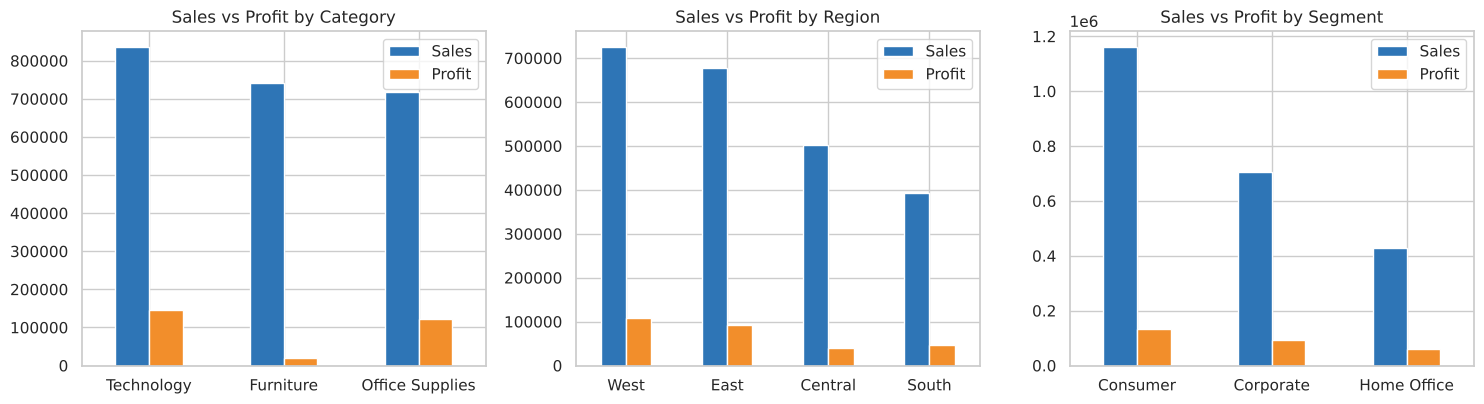

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, dim in zip(axes, ["Category", "Region", "Segment"]):
    g = df.groupby(dim)[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
    g.plot(kind="bar", ax=ax, color=["#2E75B6", "#F28E2B"], rot=0)
    ax.set_title(f"Sales vs Profit by {dim}")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

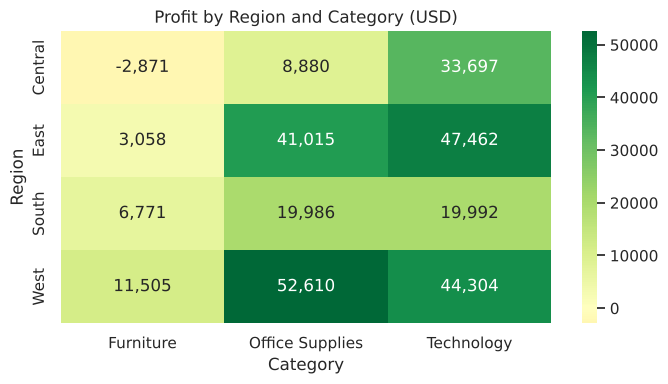

In [14]:
# Profit heatmap: Region x Category
rc = df.pivot_table(index="Region", columns="Category", values="Profit", aggfunc="sum")
plt.figure(figsize=(7, 4))
sns.heatmap(rc, annot=True, fmt=",.0f", cmap="RdYlGn", center=0)
plt.title("Profit by Region and Category (USD)")
plt.tight_layout()
plt.show()

In [15]:
# Sub-category profitability
sub = summarise(["Category", "Sub-Category"]).sort_values("Profit")
sub.head(6)

Sales     Profit  Orders  Avg_Discount  \
Category        Sub-Category                                               
Furniture       Tables       206,965.53 -17,725.48     307          0.26   
                Bookcases    114,880.00  -3,472.56     224          0.21   
Office Supplies Supplies      46,673.54  -1,189.10     187          0.08   
                Fasteners      3,024.28     949.52     215          0.08   
Technology      Machines     189,238.63   3,384.76     112          0.31   
Office Supplies Labels        12,486.31   5,546.25     346          0.07   

                              Margin %  
Category        Sub-Category            
Furniture       Tables           -8.56  
                Bookcases        -3.02  
Office Supplies Supplies         -2.55  
                Fasteners        31.40  
Technology      Machines          1.79  
Office Supplies Labels           44.42

## 7. Discount sensitivity

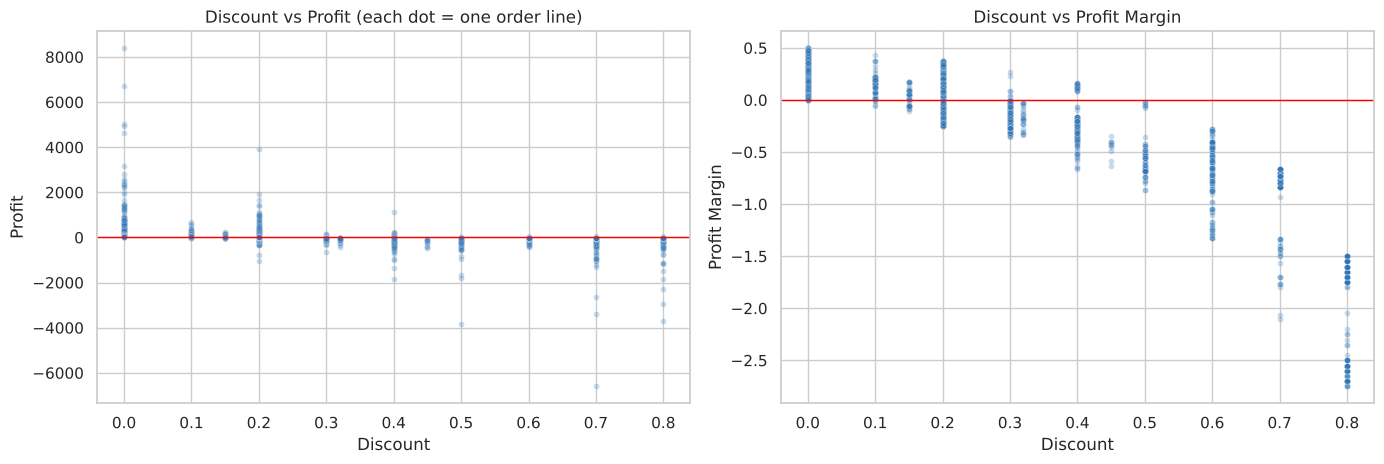

Correlation, discount vs profit:        -0.22
Correlation, discount vs profit margin: -0.86


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))

sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.25, s=18, ax=ax[0], color="#2E75B6")
ax[0].axhline(0, color="red", lw=1)
ax[0].set_title("Discount vs Profit (each dot = one order line)")
ax[0].set_xlabel("Discount")

sns.scatterplot(data=df, x="Discount", y="Profit Margin", alpha=0.25, s=18, ax=ax[1], color="#2E75B6")
ax[1].axhline(0, color="red", lw=1)
ax[1].set_title("Discount vs Profit Margin")
ax[1].set_xlabel("Discount")
plt.tight_layout()
plt.show()

print("Correlation, discount vs profit:        {:.2f}".format(df["Discount"].corr(df["Profit"])))
print("Correlation, discount vs profit margin: {:.2f}".format(df["Discount"].corr(df["Profit Margin"])))

,Order_Lines,Sales,Profit,Avg_Profit_per_Line,Margin %
Discount Band,,,,,
0%,4798,"1,087,908.47","320,987.60",66.90,29.51
0-10%,94,"54,369.35","9,029.18",96.06,16.61
10-20%,3709,"792,152.89","91,756.30",24.74,11.58
20-30%,226,"102,945.28","-10,357.22",-45.83,-10.06
30-50%,310,"195,314.76","-48,447.73",-156.28,-24.80
50%+,856,"64,228.74","-76,559.05",-89.44,-119.20


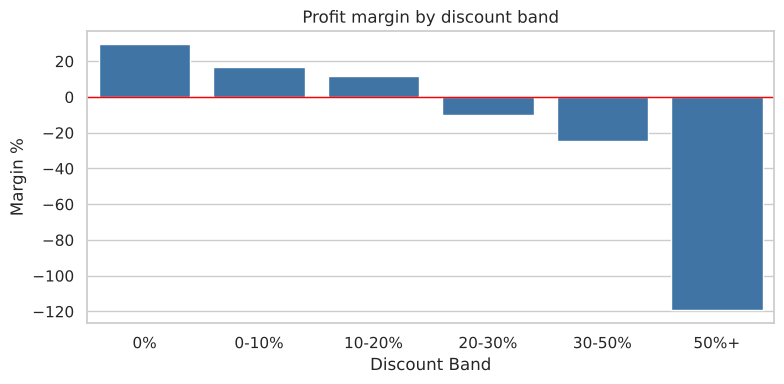

In [17]:
df["Discount Band"] = pd.cut(df["Discount"], bins=[-0.001, 0, 0.1, 0.2, 0.3, 0.5, 1.0],
                             labels=["0%", "0-10%", "10-20%", "20-30%", "30-50%", "50%+"])

bands = df.groupby("Discount Band", observed=True).agg(
    Order_Lines=("Sales", "size"), Sales=("Sales", "sum"), Profit=("Profit", "sum"),
    Avg_Profit_per_Line=("Profit", "mean"))
bands["Margin %"] = bands["Profit"] / bands["Sales"] * 100
display(bands)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=bands.index, y=bands["Margin %"], ax=ax, color="#2E75B6")
ax.axhline(0, color="red", lw=1)
ax.set_title("Profit margin by discount band")
ax.set_ylabel("Margin %")
plt.tight_layout()
plt.show()

In [18]:
# Where is the heavy discounting happening?
print("Average discount by Region:")
display(df.groupby("Region")["Discount"].mean().mul(100).round(1).sort_values(ascending=False).to_frame("Avg Discount %"))

state = df.groupby("State").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Avg_Discount=("Discount", "mean"))
state["Avg_Discount"] = state["Avg_Discount"] * 100
print("Five least profitable states:")
display(state.sort_values("Profit").head(5))

loss = df[df["Profit"] < 0]
print("Order lines losing money: {:.1%} | total losses: ${:,.0f}".format(len(loss) / len(df), loss["Profit"].sum()))
print("Share of loss-making lines with discount > 20%: {:.1%}".format((loss["Discount"] > 0.2).mean()))
heavy = df[df["Discount"] > 0.2]
print("Share of lines discounted >20% that lose money: {:.1%}".format((heavy["Profit"] < 0).mean()))

Average discount by Region:


,Avg Discount %
Region,
Central,24.00
South,14.70
East,14.50
West,10.90


Five least profitable states:


,Sales,Profit,Avg_Discount
State,,,
Texas,"170,188.05","-25,729.36",37.02
Ohio,"77,976.76","-16,959.32",32.50
Pennsylvania,"116,511.91","-15,559.96",32.86
Illinois,"80,166.10","-12,607.89",39.00
North Carolina,"55,603.16","-7,490.91",28.35


Order lines losing money: 18.7% | total losses: $-156,119
Share of loss-making lines with discount > 20%: 72.0%
Share of lines discounted >20% that lose money: 96.8%


## 8. Returns check

In [19]:
orders = df.drop_duplicates("Order ID")
return_rate = orders["Order ID"].isin(returned_ids).mean()
print("Share of orders that were returned: {:.1%}".format(return_rate))

Share of orders that were returned: 5.9%


## 9. Executive takeaways

1. **Healthy growth, with a flat 2016.** Sales fell about 3% in 2016, then grew about 29% in 2017 and 20% in 2018, reaching roughly $733K in 2018. Overall the business earned about $2.30M in sales and $286K in profit, a **12.5% margin**.
2. **Sales are strongly seasonal.** September, November and December together generate about **43% of annual sales**, and Q4 alone contributes 38%. January and February are the weakest months (about 4% and 3% of sales). Inventory, staffing and marketing spend should be planned around this pattern.
3. **Furniture is a revenue driver but not a profit driver.** Furniture brings in about $742K (32% of sales) but only about $18K in profit, a **2.5% margin**, against about 17% for Technology and Office Supplies. Tables (-8.6% margin), Bookcases (-3.0%) and Supplies (-2.5%) lose money, so pricing and discounting in these sub-categories should be reviewed first.
4. **Discounts above 20% destroy profit.** Orders with no discount earn a 29.5% margin and 10-20% discounts still earn 11.6%, but 20-30% discounts drop to -10%, 30-50% to -25% and 50%+ to **-119%**. About 97% of order lines discounted above 20% lose money, and those lines make up 72% of all loss-making lines. The correlation between discount and profit margin is about -0.86.
5. **The Central region has a discounting problem.** Central has the lowest margin (7.9%, against 13-15% in East and West) and the highest average discount (24%, against 11% in West). Texas, Ohio, Illinois and Pennsylvania are the least profitable states, all with average discounts of 32-39%, versus 5-7% in California and New York, which are among the most profitable. Furniture in the Central region is loss-making overall.
6. **Customers are loyal, and a few matter a lot.** About 98% of customers ordered more than once (median 6 orders), and the top 10% of customers account for roughly 31% of sales. Retention programmes aimed at this group would protect a large share of revenue.
7. **Segments are similar in quality.** Consumer is the largest segment (about half of sales), but Home Office and Corporate earn slightly better margins (14.0% and 13.0%, against 11.5%).
8. **Returns are modest.** About 6% of orders appear in the returns table.

**Recommendations:** cap discounts at about 20% (with approval above that), review pricing on Tables and Bookcases, investigate discount practices in the Central region and its weakest states, and align stock and marketing to the September to December peak.